Best Parameters:
{'C': 0.1, 'gamma': 0.1, 'kernel': 'rbf'}

Best Accuracy:
1.0

Test Accuracy:
1.0

Confusion Matrix:
[[12  0]
 [ 0  8]]


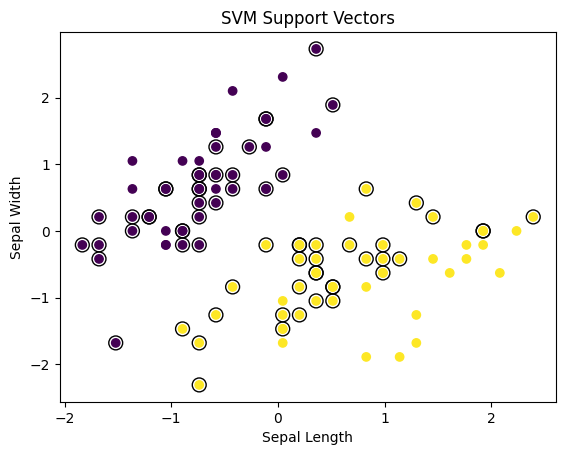

In [3]:
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV  #return best parameter value and accuracy
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix


iris = load_iris()

X = iris.data[:100, :2]
y = iris.target[:100]

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


params = {
    'kernel': ['linear', 'poly', 'rbf'],
    'C': [0.1, 1, 10],
    'gamma': [0.1, 1, 10]
}

grid = GridSearchCV(
    SVC(),
    params,
    cv=5
)

grid.fit(X_train, y_train)


print("Best Parameters:")
print(grid.best_params_)

print("\nBest Accuracy:")
print(grid.best_score_)


model = grid.best_estimator_

y_pred = model.predict(X_test)

print("\nTest Accuracy:")
print(accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


# 7. Support Vectors
plt.scatter(X[:, 0], X[:, 1], c=y)

plt.scatter(
    model.support_vectors_[:, 0],
    model.support_vectors_[:, 1],
    s=100,
    facecolors='none',
    edgecolors='black'
)

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("SVM Support Vectors")
plt.show()
